# Homework 4: Evaluation methods for Classification

Machine Learning Zoomcamp 2026
- Fabián Bayas Moscoso

In [1]:
import pandas as pd
import numpy as np


## Get Data

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


## Data preparation

    Check if the missing values are presented in the features.
    If there are missing values:
        For categorical features, replace them with 'NA'
        For numerical features, replace with with 0.0

Split the data into 3 parts with these exact calls:

In [3]:
from sklearn.model_selection import train_test_split

# Check for missing values and handle them
print("Missing values before cleaning:")
print(df.isnull().sum())
print("")

# Identify categorical and numerical columns
categorical_cols = df.select_dtypes(include=['object']).columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Fill missing values
# For categorical features, replace with 'NA'
for col in categorical_cols:
    df[col] = df[col].fillna('NA')

# For numerical features, replace with 0.0
for col in numerical_cols:
    df[col] = df[col].fillna(0.0)

print("Missing values after cleaning:")
print(df.isnull().sum())
print("")

# Split the data into 3 parts
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

print(f"Training set size: {len(df_train)}")
print(f"Validation set size: {len(df_val)}")
print(f"Test set size: {len(df_test)}")

Missing values before cleaning:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Missing values after cleaning:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Training set size: 3000
Validation set size: 1000
Test set size: 1000


## Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

    For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
    Use the training dataset for that

If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

    lead_score
    number_of_courses_viewed
    interaction_count
    annual_income


In [7]:
from sklearn.metrics import roc_auc_score

# List of numerical variables to evaluate
numerical_vars = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

# Dictionary to store AUC scores
auc_scores = {}

# Get the target variable
y_train = df_train['converted']

# Calculate AUC for each numerical variable
for var in numerical_vars:
    # Get the feature
    X = df_train[var]

    # Calculate AUC
    auc = roc_auc_score(y_train, X)

    # If AUC < 0.5, invert the variable and recalculate
    if auc < 0.5:
        X_inverted = -X
        auc = roc_auc_score(y_train, X_inverted)
        auc_scores[var] = (auc, "inverted")
        print(f"{var}: AUC = {auc:.4f} (inverted)")
    else:
        auc_scores[var] = (auc, "original")
        print(f"{var}: AUC = {auc:.4f}")

print("" + "="*60)
print("Summary of AUC scores (sorted by AUC):")
print("="*60)

# Sort by AUC score
sorted_scores = sorted(auc_scores.items(), key=lambda x: x[1][0], reverse=True)
for var, (auc, direction) in sorted_scores:
    print(f"{var:30s}: AUC = {auc:.4f} ({direction})")

print("" + "="*60)
print(f"ANSWER: The variable with the highest AUC is {sorted_scores[0][0]} with AUC = {sorted_scores[0][1][0]:.4f}")
print("="*60)

lead_score: AUC = 0.7882
number_of_courses_viewed: AUC = 0.7230
interaction_count: AUC = 0.7649
annual_income: AUC = 0.6082
Summary of AUC scores (sorted by AUC):
lead_score                    : AUC = 0.7882 (original)
interaction_count             : AUC = 0.7649 (original)
number_of_courses_viewed      : AUC = 0.7230 (original)
annual_income                 : AUC = 0.6082 (original)
ANSWER: The variable with the highest AUC is lead_score with AUC = 0.7882


## Question 2: Training the model

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

What's the AUC of this model on the validation dataset? (round to 3 digits)

    0.532
    0.632
    0.732
    0.832


In [8]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# Train the model (one-hot encoding + logistic regression)
features = [c for c in df.columns if c != 'converted']

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

y_train = df_train['converted'].values
y_val = df_val['converted'].values

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

# Evaluate on the validation dataset
auc = roc_auc_score(y_val, y_pred)

print("="*60)
print(f"ANSWER: The AUC of the model on the validation dataset is {auc:.3f}")
print("="*60)

ANSWER: The AUC of the model on the validation dataset is 0.732


## Question 3: Precision and Recall

Now let's compute precision and recall for our model.

    Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
    For each threshold, compute precision and recall
    Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

    0.43
    0.63
    0.73
    0.83


In [ ]:
import matplotlib.pyplot as plt

# Compute precision and recall for each threshold
scores = []
for t in np.arange(0.0, 1.01, 0.01):
    predict_positive = (y_pred >= t)
    actual_positive = (y_val == 1)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & ~actual_positive).sum()
    fn = (~predict_positive & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    scores.append((round(t, 2), precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

# Plot precision and recall
plt.figure(figsize=(8, 5))
plt.plot(df_scores['threshold'], df_scores['precision'], label='precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

# Ignore thresholds where both metrics are zero, then find the smallest |precision - recall|
df_valid = df_scores[(df_scores['precision'] > 0) | (df_scores['recall'] > 0)].copy()
df_valid['diff'] = (df_valid['precision'] - df_valid['recall']).abs()
best = df_valid.loc[df_valid['diff'].idxmin()]

print(df_valid.sort_values('diff').head())
print("="*60)
print(f"ANSWER: Precision and recall intersect at threshold {best['threshold']:.2f}")
print("="*60)

## Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

F 1 = 2 ⋅ P ⋅ R P + R

Where P is precision and R is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

    0.21
    0.41
    0.61
    0.81


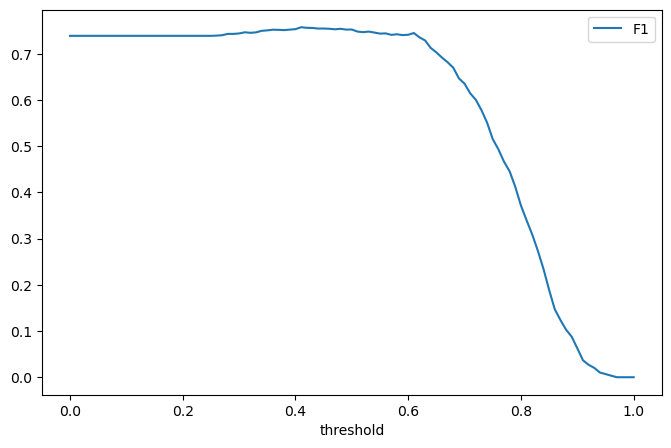

    threshold  precision    recall        f1
41       0.41   0.619048  0.976109  0.757616
42       0.42   0.620087  0.969283  0.756325
43       0.43   0.622517  0.962457  0.756032
45       0.45   0.628118  0.945392  0.754768
44       0.44   0.623608  0.955631  0.754717
ANSWER: F1 is maximal at threshold 0.41 (F1 = 0.7576)


In [9]:
# Compute F1 for each threshold using the precision and recall from Question 3
p = df_scores['precision']
r = df_scores['recall']
df_scores['f1'] = np.where((p + r) > 0, 2 * p * r / (p + r), 0.0)

# Plot F1
plt.figure(figsize=(8, 5))
plt.plot(df_scores['threshold'], df_scores['f1'], label='F1')
plt.xlabel('threshold')
plt.legend()
plt.show()

best = df_scores.loc[df_scores['f1'].idxmax()]

print(df_scores.sort_values('f1', ascending=False).head())
print("="*60)
print(f"ANSWER: F1 is maximal at threshold {best['threshold']:.2f} (F1 = {best['f1']:.4f})")
print("="*60)

## Question 5: 5-Fold CV

Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)

    Iterate over different folds of df_full_train
    Split the data into train and validation
    Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

    0.001
    0.007
    0.013
    0.060


In [10]:
from sklearn.model_selection import KFold

def train(df_train, y_train, C=1.0):
    dicts = df_train[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

def predict(df, dv, model):
    dicts = df[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

# 5-fold cross-validation on df_full_train
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_vl = df_full_train.iloc[val_idx]

    y_tr = df_tr['converted'].values
    y_vl = df_vl['converted'].values

    dv_fold, model_fold = train(df_tr, y_tr, C=1.0)
    y_pred_fold = predict(df_vl, dv_fold, model_fold)

    scores.append(roc_auc_score(y_vl, y_pred_fold))

print("AUC per fold:", np.round(scores, 3))
print("="*60)
print(f"ANSWER: mean AUC = {np.mean(scores):.3f}, std = {np.std(scores):.3f}")
print("="*60)

AUC per fold: [0.731 0.73  0.736 0.741 0.721]
ANSWER: mean AUC = 0.732, std = 0.007


## Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter C

    Iterate over the following C values: [0.000001, 0.001, 1]
    Initialize KFold with the same parameters as previously
    Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

    0.000001
    0.001
    1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

In [11]:
# 5-fold cross-validation for different values of C
results = []
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_vl = df_full_train.iloc[val_idx]

        y_tr = df_tr['converted'].values
        y_vl = df_vl['converted'].values

        dv_fold, model_fold = train(df_tr, y_tr, C=C)
        y_pred_fold = predict(df_vl, dv_fold, model_fold)

        scores.append(roc_auc_score(y_vl, y_pred_fold))

    mean_auc = round(np.mean(scores), 3)
    std_auc = round(np.std(scores), 3)
    results.append((C, mean_auc, std_auc))
    print(f"C={C}: mean AUC = {mean_auc:.3f} +- {std_auc:.3f}")

# Best mean AUC; ties broken by lowest std, then smallest C
df_results = pd.DataFrame(results, columns=['C', 'mean_auc', 'std_auc'])
best = df_results.sort_values(['mean_auc', 'std_auc', 'C'], ascending=[False, True, True]).iloc[0]

print("="*60)
print(f"ANSWER: The best C is {best['C']:g} (mean AUC = {best['mean_auc']:.3f}, std = {best['std_auc']:.3f})")
print("="*60)

C=1e-06: mean AUC = 0.617 +- 0.019
C=0.001: mean AUC = 0.749 +- 0.010
C=1: mean AUC = 0.732 +- 0.007
ANSWER: The best C is 0.001 (mean AUC = 0.749, std = 0.010)
